# Postpartum Depression & Anxiety Prediction — Stage 1
### Step-by-Step Baseline Project (Fully Separated Tasks)

Each task is separated into its own individual cell so each action is easy to run, understand, and present.

In [11]:
# Task 1: Import Data Processing Libraries
import pandas as pd
import numpy as np

In [12]:
# Task 2: Import Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# Task 3: Import Machine Learning Tools from Scikit-Learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [14]:
# Task 4: Load the Dataset from CSV file
df = pd.read_csv('post natal data.csv')

In [15]:
# Task 5: Check the Number of Rows and Columns
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 1503
Columns : 11


In [16]:
# Task 6: Preview the First 5 Rows of Raw Data
df.head()

,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [17]:
# Task 7: Check for Missing Values in Each Column
df.isnull().sum()

Timestamp                                     0
Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling anxious                               0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
dtype: int64

In [18]:
# Task 8: Fill Missing Values with the Most Common Value (Mode)
for col in df.columns:
    if df[col].isnull().sum() > 0:
        most_common = df[col].mode()[0]
        df[col] = df[col].fillna(most_common)

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [19]:
# Task 9: Drop the 'Timestamp' Column (Not a Predictive Feature)
df = df.drop(columns=['Timestamp'])
print("Columns after dropping Timestamp:", df.shape[1])

Columns after dropping Timestamp: 10


In [20]:
# Task 10: Count Duplicate Rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 1177


In [21]:
# Task 11: Remove Duplicate Rows
df = df.drop_duplicates().reset_index(drop=True)
print("Clean dataset rows:", df.shape[0])

Clean dataset rows: 326


In [22]:
# Task 12: Convert All Text Columns to Numbers Automatically
le = LabelEncoder()
for col in df.columns:
    df[col] = le.fit_transform(df[col])

In [23]:
# Task 13: Preview the Encoded Numeric Data
df.head()

,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,2,1,2,2,1,1,2,2
1,3,2,0,0,2,2,0,2,2,0
2,2,2,0,2,2,2,1,1,1,0
3,2,2,2,2,2,0,1,0,0,0
4,3,2,0,1,2,0,1,1,2,0


In [24]:
# Task 14: Count Target Values (0 = No Anxiety, 1 = High Anxiety)
target_counts = df['Feeling anxious'].value_counts()
print(target_counts)

Feeling anxious
1    189
0    137
Name: count, dtype: int64


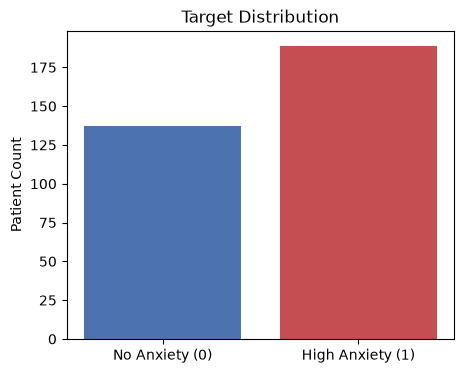

In [25]:
# Task 15: Plot Target Class Distribution
plt.figure(figsize=(5, 4))
plt.bar(['No Anxiety (0)', 'High Anxiety (1)'], [target_counts[0], target_counts[1]], color=['#4C72B0', '#C44E52'])
plt.title('Target Distribution')
plt.ylabel('Patient Count')
plt.show()

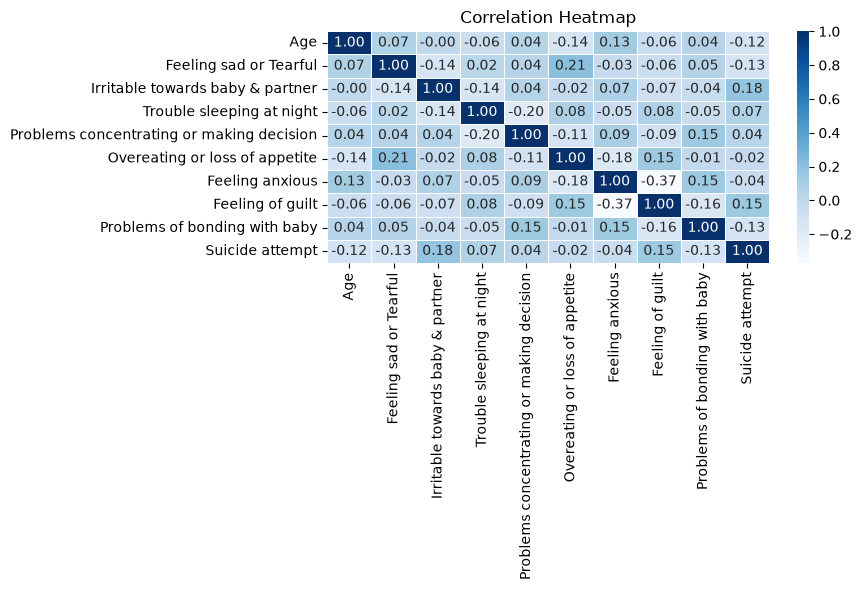

In [26]:
# Task 16: Plot Feature Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [27]:
# Task 17: Separate Features (X) and Target (y)
X = df.drop(columns=['Feeling anxious'])
y = df['Feeling anxious']

In [28]:
# Task 18: Split Data into 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows :", len(X_train))
print("Testing rows  :", len(X_test))

Training rows : 260
Testing rows  : 66


In [29]:
# Task 19: Create Logistic Regression Model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

In [30]:
# Task 20: Train Logistic Regression Model
lr_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

Logistic Regression training complete.


In [31]:
# Task 21: Make Predictions with Logistic Regression
lr_train_preds = lr_model.predict(X_train)
lr_test_preds = lr_model.predict(X_test)

In [32]:
# Task 22: Check Logistic Regression Accuracy
lr_train_acc = accuracy_score(y_train, lr_train_preds) * 100
lr_test_acc = accuracy_score(y_test, lr_test_preds) * 100

print(f"Training Accuracy : {lr_train_acc:.1f}%")
print(f"Testing Accuracy  : {lr_test_acc:.1f}%")

Training Accuracy : 69.6%
Testing Accuracy  : 69.7%


In [33]:
# Task 23: Logistic Regression Classification Report
print(classification_report(y_test, lr_test_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.68      0.54      0.60        28
High Anxiety       0.70      0.82      0.76        38

    accuracy                           0.70        66
   macro avg       0.69      0.68      0.68        66
weighted avg       0.69      0.70      0.69        66



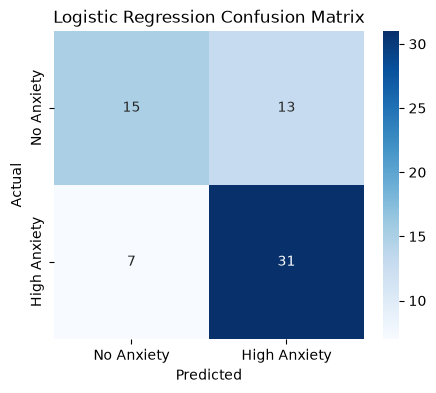

In [34]:
# Task 24: Plot Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, lr_test_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [35]:
# Task 25: Create Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

In [36]:
# Task 26: Train Random Forest Model
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")

Random Forest training complete.


In [37]:
# Task 27: Make Predictions with Random Forest
rf_train_preds = rf_model.predict(X_train)
rf_test_preds = rf_model.predict(X_test)

In [38]:
# Task 28: Check Random Forest Accuracy
rf_train_acc = accuracy_score(y_train, rf_train_preds) * 100
rf_test_acc = accuracy_score(y_test, rf_test_preds) * 100

print(f"Training Accuracy : {rf_train_acc:.1f}%")
print(f"Testing Accuracy  : {rf_test_acc:.1f}%")

Training Accuracy : 87.7%
Testing Accuracy  : 78.8%


In [39]:
# Task 29: Random Forest Classification Report
print(classification_report(y_test, rf_test_preds, target_names=['No Anxiety', 'High Anxiety']))

              precision    recall  f1-score   support

  No Anxiety       0.85      0.61      0.71        28
High Anxiety       0.76      0.92      0.83        38

    accuracy                           0.79        66
   macro avg       0.81      0.76      0.77        66
weighted avg       0.80      0.79      0.78        66



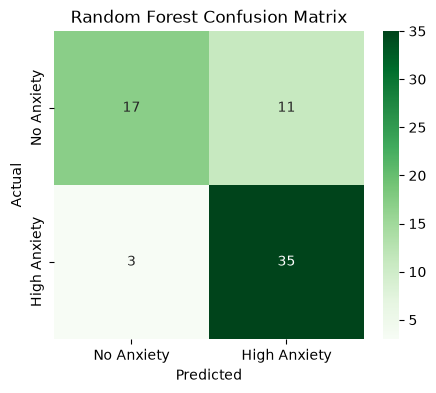

In [40]:
# Task 30: Plot Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_test_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Anxiety', 'High Anxiety'],
            yticklabels=['No Anxiety', 'High Anxiety'])
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [41]:
# Task 31: Create Model Comparison Table
comparison_table = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Training Accuracy (%)': [round(lr_train_acc, 1), round(rf_train_acc, 1)],
    'Testing Accuracy (%)': [round(lr_test_acc, 1), round(rf_test_acc, 1)]
})
comparison_table

,Model,Training Accuracy (%),Testing Accuracy (%)
0,Logistic Regression,69.6,69.7
1,Random Forest,87.7,78.8


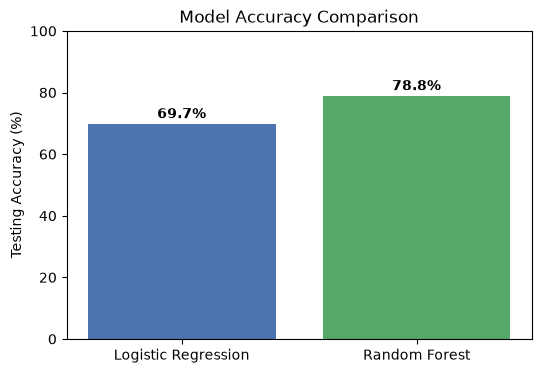

In [42]:
# Task 32: Plot Model Comparison Bar Chart
plt.figure(figsize=(6, 4))
plt.bar(['Logistic Regression', 'Random Forest'], [lr_test_acc, rf_test_acc], color=['#4C72B0', '#55A868'])
plt.ylabel('Testing Accuracy (%)')
plt.ylim(0, 100)
plt.title('Model Accuracy Comparison')
for i, v in enumerate([lr_test_acc, rf_test_acc]):
    plt.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.show()

In [43]:
# Task 33: Select a Real Patient from Test Data
sample_patient = X_test.iloc[[0]]
actual_status = y_test.iloc[0]
print("Selected Patient Features:")
print(sample_patient)
print()
print("Actual Diagnosis:", "High Anxiety" if actual_status == 1 else "No Anxiety")

Selected Patient Features:
     Age  Feeling sad or Tearful  Irritable towards baby & partner  \
325    0                       1                                 1   

     Trouble sleeping at night  Problems concentrating or making decision  \
325                          1                                          0   

     Overeating or loss of appetite  Feeling of guilt  \
325                               0                 0   

     Problems of bonding with baby  Suicide attempt  
325                              0                0  

Actual Diagnosis: No Anxiety


In [44]:
# Task 34: Predict Sample Patient with Both Models
lr_patient_pred = lr_model.predict(sample_patient)[0]
rf_patient_pred = rf_model.predict(sample_patient)[0]

print("Logistic Regression Prediction :", "High Anxiety" if lr_patient_pred == 1 else "No Anxiety")
print("Random Forest Prediction       :", "High Anxiety" if rf_patient_pred == 1 else "No Anxiety")

Logistic Regression Prediction : High Anxiety
Random Forest Prediction       : No Anxiety
